## Item Sink Data for Price and Volume


**Imports used for this notebook**

In [499]:
import requests
import time
from bs4 import BeautifulSoup as bs
import pandas as pd
import numpy as np
import seaborn as sb
import matplotlib.pyplot as plt
import re
HEADERS = {"User-Agent": "WEBDATASCIENCE OSRS Research Project/1.0, simon.spillane@colorado.edu"}


**Current Item Sink List from the OSRS Wiki**

In [426]:
CurrentSink = requests.get("https://oldschool.runescape.wiki/w/Grand_Exchange#Items_regulated_via_item_sink",headers=HEADERS).text


In [430]:
# soup from request
sinkSoup = bs(CurrentSink)

In [432]:
# create a dict for each item in the list and print 
CurrentSinkListResults = {}

for th in sinkSoup.find_all('th'):
    if th.get_text(strip=True) == 'Item Sink List':
        row = th.find_parent('tr')
        for sib in row.find_next_siblings('tr'):
            if sib.find('th'):          # next section heading, stop
                break
            for li in sib.select('td > ul > li'):
                a = li.find('a', title=True)           # e.g. Chambers of Xeric
                if not a:
                    continue
                # text that belongs to this <li> only, not the nested <ul>
                label = ''.join(li.find_all(string=True, recursive=False)).strip()
                items = [x['title'] for x in li.select('ul a[title]')]
                CurrentSinkListResults[a['title']] = {'label': label, 'items': items}
        break
CurrentSinkListResults

{'Chambers of Xeric': {'label': 'uniques',
  'items': ['Chambers of Xeric',
   'Ancestral hat',
   'Ancestral robe top',
   'Ancestral robe bottom',
   "Dinh's bulwark",
   'Elder maul',
   'Kodai wand',
   'Prayer scroll',
   'Arcane prayer scroll',
   'Dexterous prayer scroll',
   'Twisted buckler',
   'Twisted bow']},
 'Theatre of Blood': {'label': 'uniques',
  'items': ['Theatre of Blood',
   'Avernic defender hilt',
   'Sanguinesti staff',
   'Scythe of Vitur']},
 'Tombs of Amascut': {'label': 'uniques',
  'items': ['Tombs of Amascut',
   "Elidinis' ward",
   'Lightbearer',
   'Masori mask (f)',
   'Masori body (f)',
   'Masori chaps (f)',
   "Osmumten's fang",
   "Tumeken's shadow"]},
 'Dagannoth Kings': {'label': 'uniques',
  'items': ['Dagannoth Kings', 'Archers ring', 'Berserker ring']},
 'God Wars Dungeon': {'label': 'uniques',
  'items': ['God Wars Dungeon',
   'Armadyl armour',
   'Bandos armour',
   'Bandos boots',
   'Godsword',
   'Ancient godsword',
   'Armadyl godsword

## Historical Wiki Data for Item Sink

In [400]:
# csv created in Historical Sink Items Wiki
ItemSinkDF = pd.read_csv("ItemSinkList.csv")
ItemSinkDF

,item,first_seen,last_seen,n_revisions,still_listed,still_here
0,abyssal bludgeon,2022-03-29 07:11:23+00:00,2026-10-16 02:02:43+00:00,112,True,True
1,amulet of torture,2022-03-29 07:11:23+00:00,2026-10-16 02:02:43+00:00,112,True,True
2,ancestral hat,2022-03-29 07:11:23+00:00,2026-10-16 02:02:43+00:00,112,True,True
3,ancestral robe bottom,2022-03-29 07:11:23+00:00,2026-10-16 02:02:43+00:00,112,True,True
4,ancestral robe top,2022-03-29 07:11:23+00:00,2026-10-16 02:02:43+00:00,112,True,True
...,...,...,...,...,...,...
69,zamorak godsword,2022-03-29 07:11:23+00:00,2026-10-16 02:02:43+00:00,112,True,True
70,zamorakian spear,2022-03-29 07:11:23+00:00,2026-10-16 02:02:43+00:00,112,True,True
71,zaryte crossbow,2023-01-11 12:39:29+00:00,2026-10-16 02:02:43+00:00,94,True,True
72,zaryte vambraces,2023-01-11 12:39:29+00:00,2026-10-16 02:02:43+00:00,94,True,True


**Pull the item names out of the dataframe and create a set**

In [441]:
# check the number of unique items in the list removing non-item elements,
# this returns a set used in the next code block

sinkList = []
itemc = 0

exceptions = [
    "Chambers of Xeric", "Theatre of Blood", "Tombs of Amascut",
    "God Wars Dungeon", "Dagannoth Kings",
    "Nightmare", "Slayer",
]

def is_excepted(item):
    name = str(item).lower()
    return any(ex.lower() in name for ex in exceptions)

sinkList = []

for span in ItemSinkDF.columns.get_level_values(0).unique():
    for item in ItemSinkDF['item']:
        if is_excepted(item):
            continue
        sinkList.append(item)

item_set = set()
for item in sinkList:
    item_set.add(item)
    
print(len(item_set))
item_set

73


{'abyssal bludgeon',
 'amulet of torture',
 'ancestral hat',
 'ancestral robe bottom',
 'ancestral robe top',
 'ancient godsword',
 'arcane prayer scroll',
 'arcane spirit shield',
 'archers ring',
 'armadyl chainskirt',
 'armadyl chestplate',
 'armadyl godsword',
 'armadyl helmet',
 'avernic defender hilt',
 'bandos boots',
 'bandos chestplate',
 'bandos godsword',
 'bandos tassets',
 'berserker ring',
 'burning claws',
 'dark bow',
 'dexterous prayer scroll',
 "dinh's bulwark",
 'dragon hunter lance',
 'dragon pickaxe',
 'dragon warhammer',
 'elder maul',
 'eldritch orb',
 "elidinis' ward",
 'godsword',
 'harmonised orb',
 "hydra's claw",
 "inquisitor's great helm",
 "inquisitor's hauberk",
 "inquisitor's mace",
 'kodai insignia',
 'kodai wand',
 'kraken tentacle',
 'lightbearer',
 'masori body (f)',
 'masori chaps (f)',
 'masori mask (f)',
 'necklace of anguish',
 'occult necklace',
 "osmumten's fang",
 'prayer scroll',
 'ring of suffering',
 'sanguinesti staff (uncharged)',
 'sarac

**Using the results from item_set find all the item ids for the Sink List**

In [435]:
URL = "https://api.weirdgloop.org/exchange/history/osrs/latest"

def fetch_item_ids(names, chunk_size=50, min_interval=1.0, max_requests=20,
                   max_retries=3):
    names = pd.Series(names).dropna().astype(str).str.strip()
    names = names[names != ""].drop_duplicates().tolist()

    ids, missing = {}, []
    requests_made = 0
    last_request = 0.0

    for i in range(0, len(names), chunk_size):
        chunk = names[i:i + chunk_size]

        if requests_made >= max_requests:
            print(f"Request cap ({max_requests}) reached; skipping remaining names.")
            missing.extend(names[i:])
            break

        data = None
        for attempt in range(max_retries):
            wait = min_interval - (time.monotonic() - last_request)
            if wait > 0:
                time.sleep(wait)

            r = requests.get(URL, params={"name": "|".join(chunk)},
                             headers=HEADERS, timeout=30)
            last_request = time.monotonic()
            requests_made += 1

            if r.status_code == 429 or r.status_code >= 500:
                time.sleep(float(r.headers.get("Retry-After", 2 ** attempt)))
                if requests_made >= max_requests:
                    break
                continue

            if r.status_code in (400, 404):
                data = {}
                break

            r.raise_for_status()
            data = r.json()
            break

        if not data or data.get("success") is False:
            missing.extend(chunk)
            continue

        found = {k.lower(): v["id"] for k, v in data.items()}
        for n in chunk:
            if n.lower() in found:
                ids[n] = int(found[n.lower()])
            else:
                missing.append(n)

    print(f"{requests_made} requests, {len(ids)} found, {len(missing)} missing")
    return ids, missing


ids, missing = fetch_item_ids(list(item_set))

2 requests, 71 found, 2 missing


In [442]:
# check that nothing important is missing this should be ['godsword', 'prayer scroll']
missing

['godsword', 'prayer scroll']

**Create a DataFrame for the Item Names with ID**

In [444]:
ItemIdDF = pd.DataFrame({"item": list(ids), "id": list(ids.values())})

## Historical Price/Volume Data for items

In [445]:
def fetch_price_history(item_df, endpoint="all", chunk_size=1, min_interval=1.0,
                        max_requests=1000, start_date=None, end_date=None):
    url = f"https://api.weirdgloop.org/exchange/history/osrs/{endpoint}"

    ids = item_df["id"].dropna().astype(int).drop_duplicates().tolist()
    id_to_name = {}
    if "item" in item_df.columns:
        id_to_name = (item_df.dropna(subset=["id"])
                             .assign(id=lambda d: d["id"].astype(int))
                             .drop_duplicates("id")
                             .set_index("id")["item"].to_dict())

    frames, failed = [], []
    requests_made, last_request = 0, 0.0

    for i in range(0, len(ids), chunk_size):
        chunk = ids[i:i + chunk_size]

        if requests_made >= max_requests:
            print(f"Request cap ({max_requests}) reached; skipping remaining ids.")
            failed.extend(ids[i:])
            break

        wait = min_interval - (time.monotonic() - last_request)
        if wait > 0:
            time.sleep(wait)

        try:
            r = requests.get(url,
                             params={"id": "|".join(map(str, chunk))},
                             headers=HEADERS, timeout=60)
            last_request = time.monotonic()
            requests_made += 1
            r.raise_for_status()
            data = r.json()
        except (requests.RequestException, ValueError) as e:
            print(f"Chunk starting at index {i} failed: {e}")
            failed.extend(chunk)
            continue

        if data.get("success") is False:
            print(f"API error for chunk at index {i}: {data.get('error', data)}")
            failed.extend(chunk)
            continue

        got = set()
        for key, records in data.items():
            if not str(key).isdigit() or not isinstance(records, list) or not records:
                continue
            f = pd.DataFrame(records)
            f["id"] = int(key)
            frames.append(f)
            got.add(int(key))

        failed.extend(x for x in chunk if x not in got)

    cols = ["id", "item", "timestamp", "price", "volume", "date"]
    if not frames:
        print(f"{requests_made} requests, nothing returned, {len(failed)} failed")
        return pd.DataFrame(columns=cols), failed

    history = pd.concat(frames, ignore_index=True)
    history["date"] = pd.to_datetime(history["timestamp"], unit="ms")
    history["item"] = history["id"].map(id_to_name)

    if start_date is not None:
        history = history[history["date"] >= start_date]
    if end_date is not None:
        history = history[history["date"] < end_date]

    history = history[[c for c in cols if c in history.columns]]
    print(f"{requests_made} requests, {history['id'].nunique()} items, "
          f"{len(history)} rows, {len(failed)} failed")
    return history.reset_index(drop=True), failed

**Use Item ID Dataframe to find Historical Price Info and save to CSV**

In [446]:
history, failed = fetch_price_history(ItemIdDF, endpoint="all", min_interval=1.0)
history.to_csv("sink_history_all.csv", index=False)

71 requests, 71 items, 255594 rows, 0 failed


**Create Dataframe from sink_history_all.csv**

In [455]:
sinkHistDF = pd.read_csv('sink_history_all.csv')

**Add first_seen and last_seen columns new Dataframe**

In [456]:
sinkHistDF = sinkHistDF.merge(
    ItemSinkDF[["item", "first_seen", "last_seen"]],
    on="item",
    how="left",
    validate="many_to_one",
)

In [477]:
# the only NaN or NaT values should be for volume data that does not exist
sinkHistDF

,id,item,timestamp,price,volume,date,first_seen,last_seen
0,6733,archers ring,1427500800000,3603798,NaN,2015-03-28 00:00:00,2022-03-29 07:11:23+00:00,2026-10-16 02:02:43+00:00
1,6733,archers ring,1427587200000,3593285,NaN,2015-03-29 00:00:00,2022-03-29 07:11:23+00:00,2026-10-16 02:02:43+00:00
2,6733,archers ring,1427673600000,3554174,NaN,2015-03-30 00:00:00,2022-03-29 07:11:23+00:00,2026-10-16 02:02:43+00:00
3,6733,archers ring,1427760000000,3531218,NaN,2015-03-31 00:00:00,2022-03-29 07:11:23+00:00,2026-10-16 02:02:43+00:00
4,6733,archers ring,1427846400000,3516752,NaN,2015-04-01 00:00:00,2022-03-29 07:11:23+00:00,2026-10-16 02:02:43+00:00
...,...,...,...,...,...,...,...,...
255589,12825,arcane spirit shield,1794550859000,98896275,4.0,2026-11-13 06:20:59,2022-03-29 07:11:23+00:00,2026-10-16 02:02:43+00:00
255590,12825,arcane spirit shield,1794564190000,98896275,7.0,2026-11-13 10:03:10,2022-03-29 07:11:23+00:00,2026-10-16 02:02:43+00:00
255591,12825,arcane spirit shield,1794577380000,98896275,8.0,2026-11-13 13:43:00,2022-03-29 07:11:23+00:00,2026-10-16 02:02:43+00:00
255592,12825,arcane spirit shield,1794591372000,98896275,15.0,2026-11-13 17:36:12,2022-03-29 07:11:23+00:00,2026-10-16 02:02:43+00:00


In [484]:
# fix for datetime issues that was causing an error 
sinkHistDF['date'] = pd.to_datetime(sinkHistDF['date'])
print(sinkHistDF['date'].dtype)

datetime64[us]


**Function for Price Plots**

In [490]:
def plot_items_price(df, items, freq="D", title=None, log=False,
                     skip_last_seen="2026-10-16 02:02:43+00:00"):
    if isinstance(items, str):
        items = [items]

    sub = df[df["item"].isin(items)]

    prices = (
        sub.groupby(["item", pd.Grouper(key="date", freq=freq)])["price"]
        .mean()
        .unstack("item")
    )

    ax = prices.plot(figsize=(11, 5), title=title or ", ".join(items), logy=log)

    skip_ts = pd.to_datetime(skip_last_seen, utc=True) if skip_last_seen else None

    def to_utc(x):
        return pd.to_datetime(x, errors="coerce", utc=True)

    def to_naive(x):
        return x.tz_localize(None) if pd.notna(x) else x

    multi = len(items) > 1
    seen = sub.groupby("item")[["first_seen", "last_seen"]].first()

    for item, row in seen.iterrows():
        first = to_utc(row["first_seen"])
        last = to_utc(row["last_seen"])
        prefix = f"{item} " if multi else ""   # include item name only when plotting several

        if pd.notna(first):
            ax.axvline(to_naive(first), color="green", linestyle=":", linewidth=1.5,
                       label=f"{prefix}First Seen: {first:%Y-%m-%d}")

        # skip last_seen if it matches the excluded timestamp
        if pd.notna(last) and not (skip_ts is not None and last == skip_ts):
            ax.axvline(to_naive(last), color="red", linestyle=":", linewidth=1.5,
                       label=f"{prefix}Last Seen: {last:%Y-%m-%d}")

    ax.legend()
    ax.set_ylabel("Price (gp)")
    ax.set_xlabel("")
    ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

**Function for Volume Plots**

In [481]:
def plot_items_volume(df, items, freq="D", title=None, log=False, vline=None,
                      skip_last_seen="2026-10-16 02:02:43+00:00"):
    if isinstance(items, str):
        items = [items]

    sub = df[df["item"].isin(items)]

    volumes = (
        sub.groupby(["item", pd.Grouper(key="date", freq=freq)])["volume"]
        .mean()
        .unstack("item")
    )

    ax = volumes.plot(figsize=(11, 5), title=title or ", ".join(items), logy=log)

    skip_ts = pd.to_datetime(skip_last_seen, utc=True) if skip_last_seen else None

    def to_utc(x):
        return pd.to_datetime(x, errors="coerce", utc=True)

    def to_naive(x):
        return x.tz_localize(None) if pd.notna(x) else x

    multi = len(items) > 1
    seen = sub.groupby("item")[["first_seen", "last_seen"]].first()

    for item, row in seen.iterrows():
        first = to_utc(row["first_seen"])
        last = to_utc(row["last_seen"])
        prefix = f"{item} " if multi else ""   # include item name only when plotting several

        if pd.notna(first):
            ax.axvline(to_naive(first), color="green", linestyle=":", linewidth=1.5,
                       label=f"{prefix}First Seen: {first:%Y-%m-%d}")

        # skip last_seen if it matches the excluded timestamp
        if pd.notna(last) and not (skip_ts is not None and last == skip_ts):
            ax.axvline(to_naive(last), color="red", linestyle=":", linewidth=1.5,
                       label=f"{prefix}Last Seen: {last:%Y-%m-%d}")

    ax.legend()
    ax.set_ylabel("Volume")
    ax.set_xlabel("")
    ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

**Plot Price for each Item in DF**

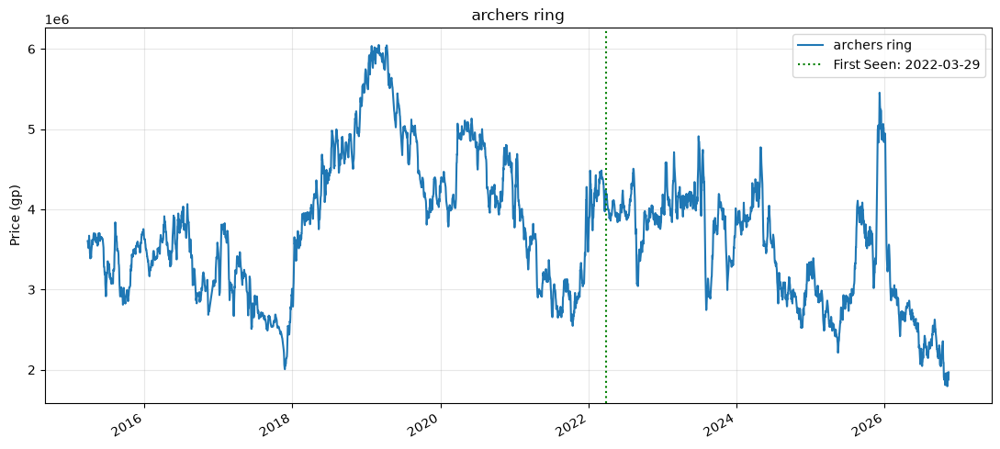

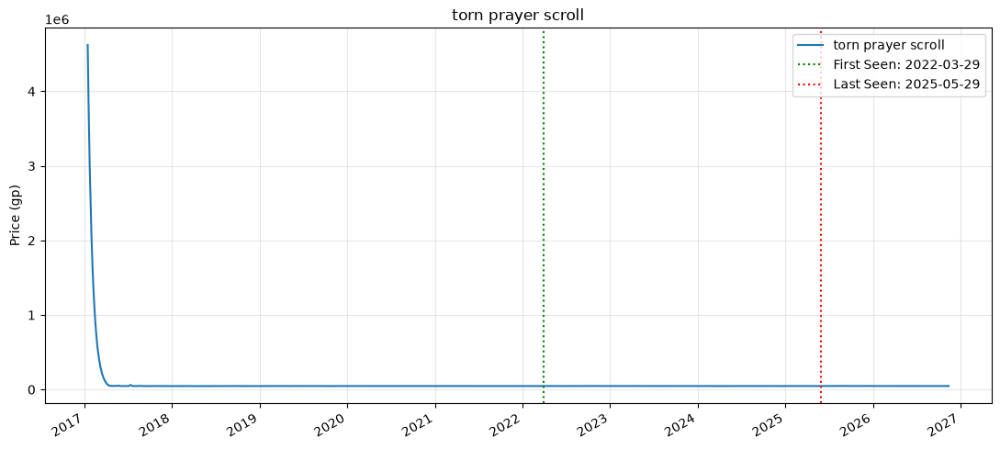

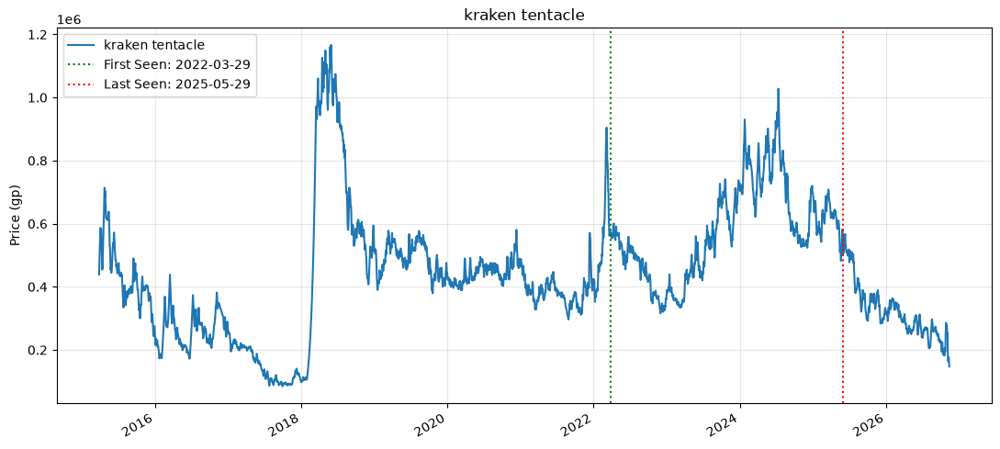

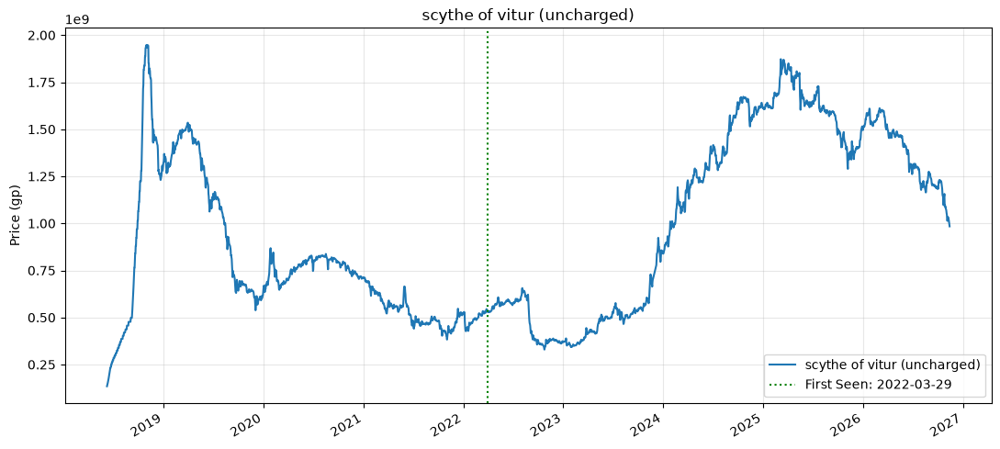

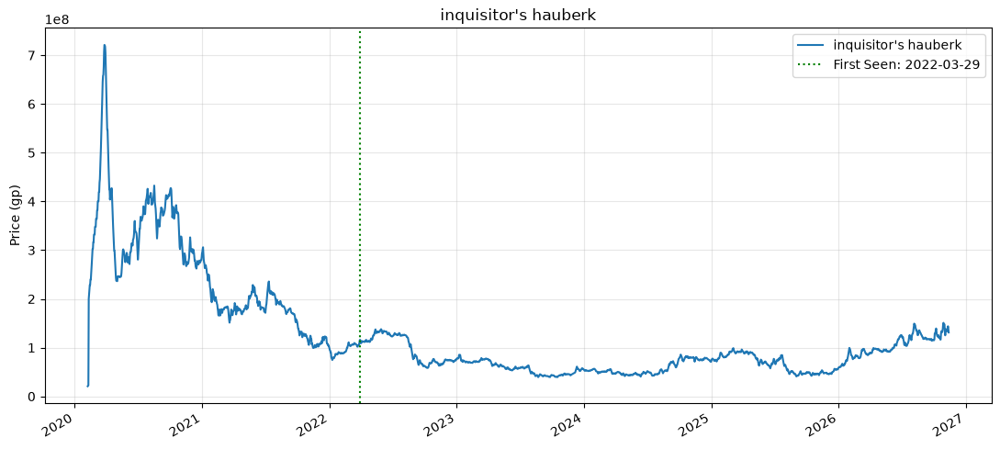

...

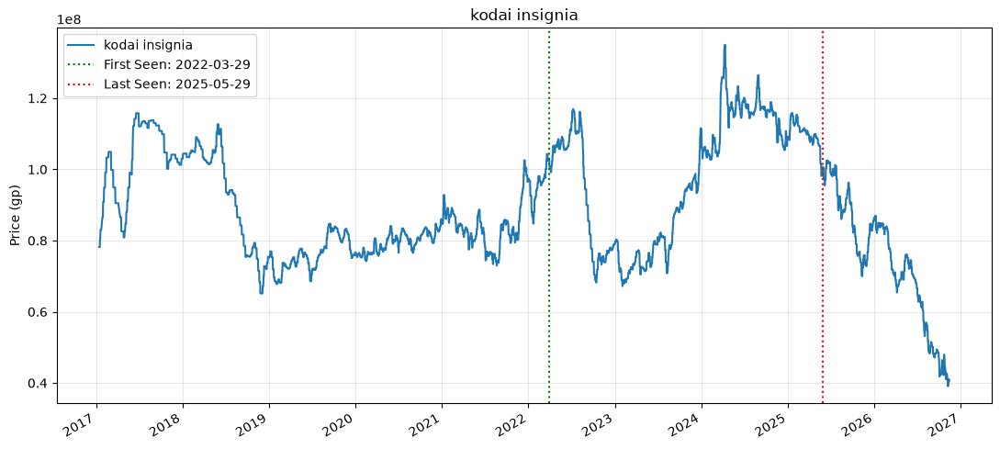

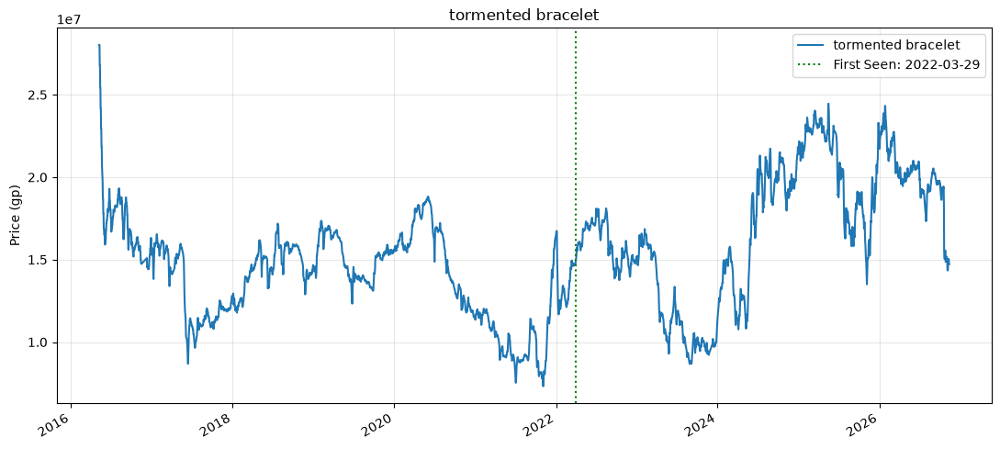

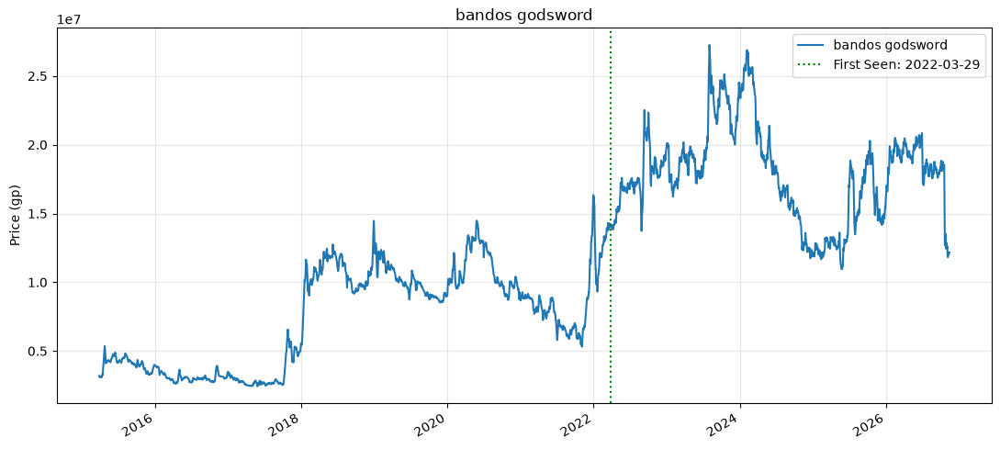

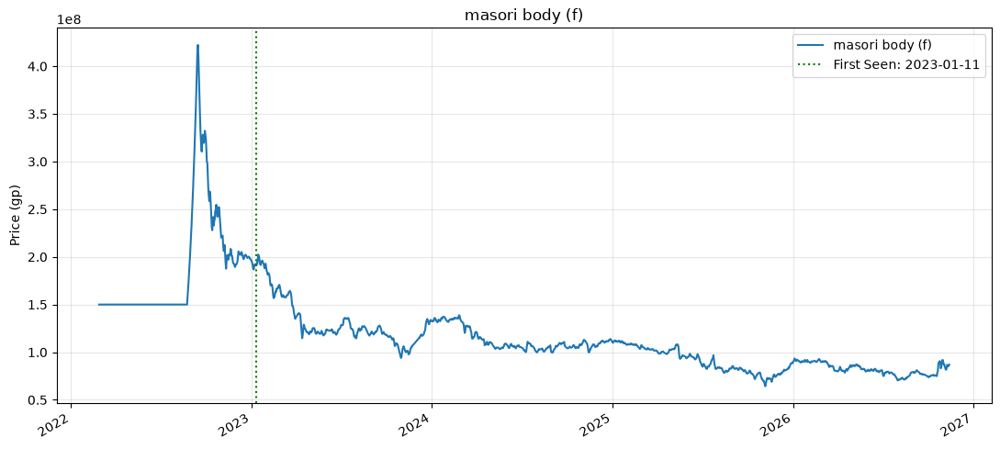

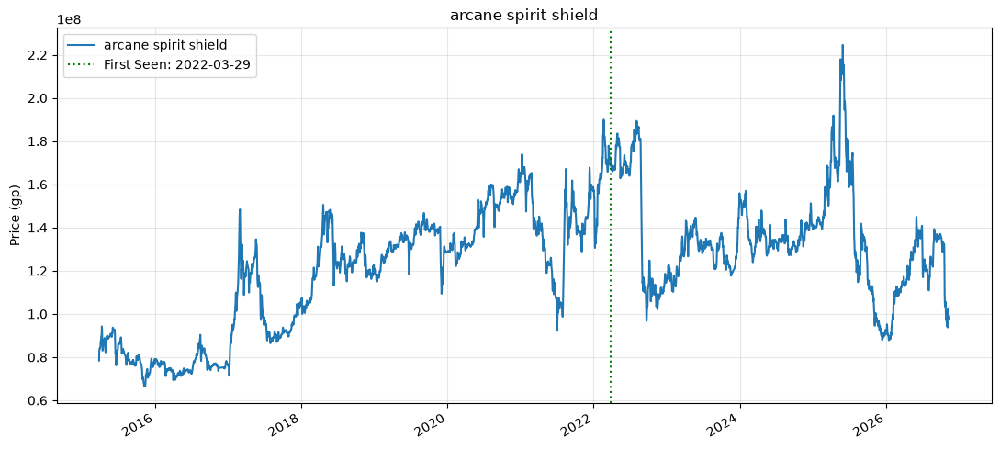

In [491]:
for item in unique_items:
    plot_items_price(sinkHistDF, item)

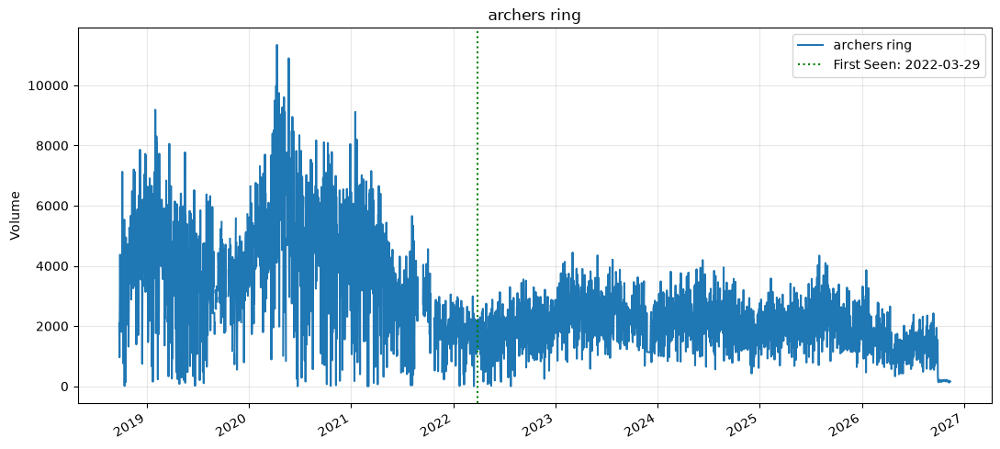

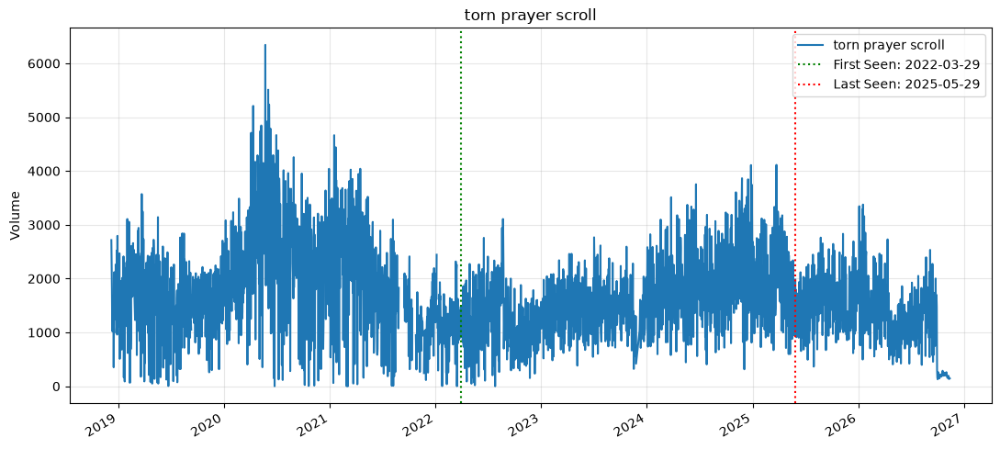

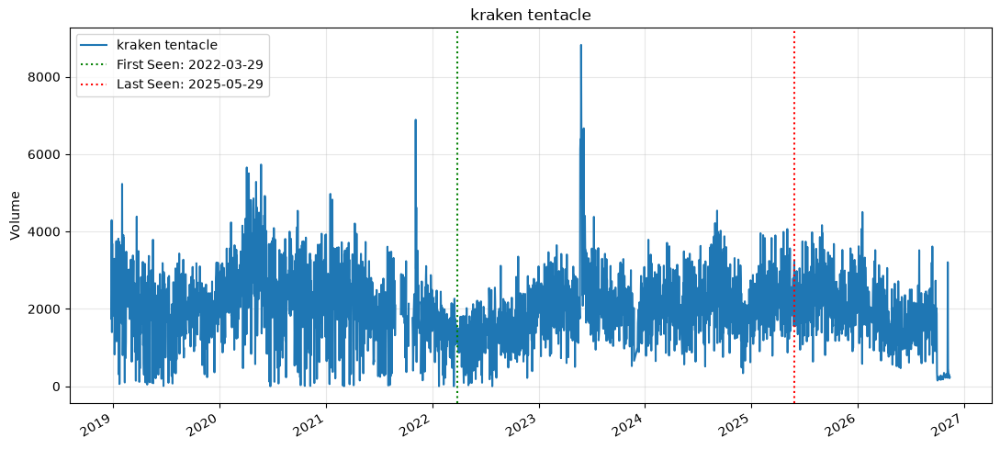

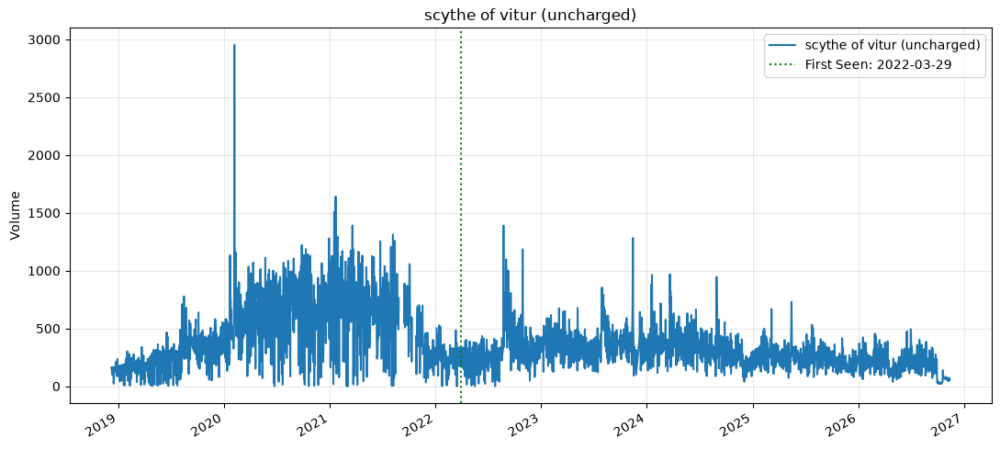

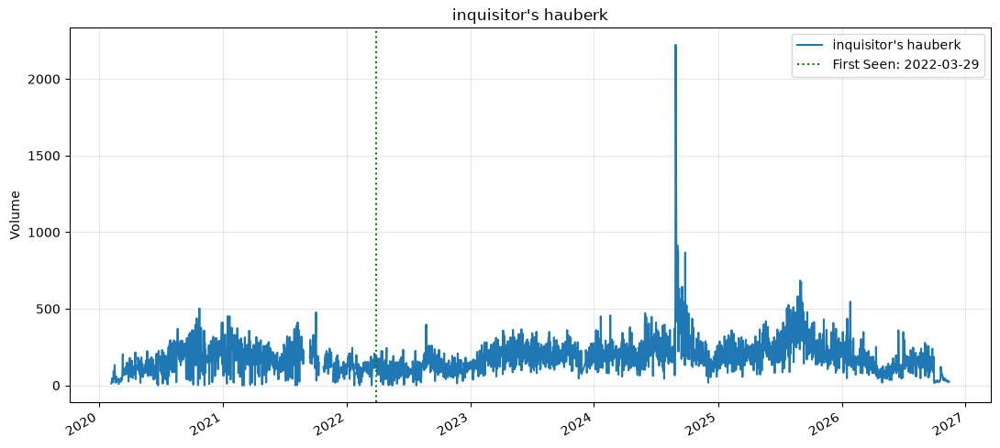

...

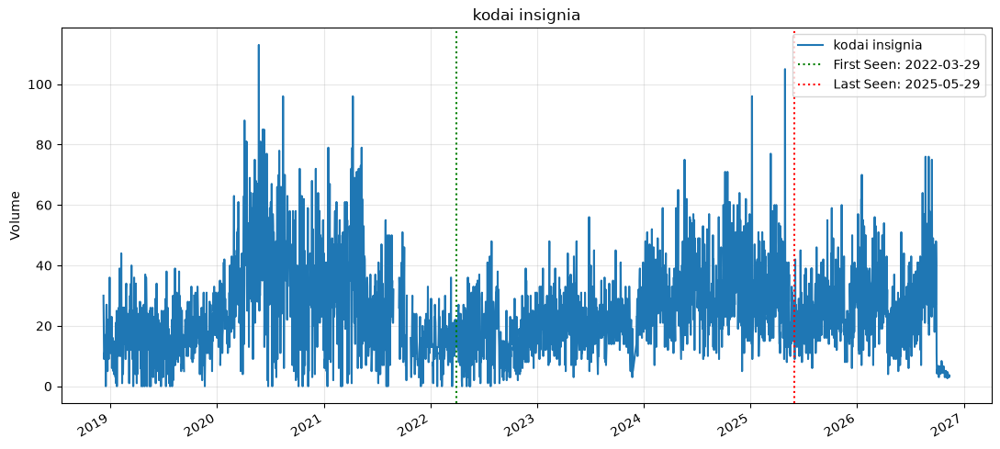

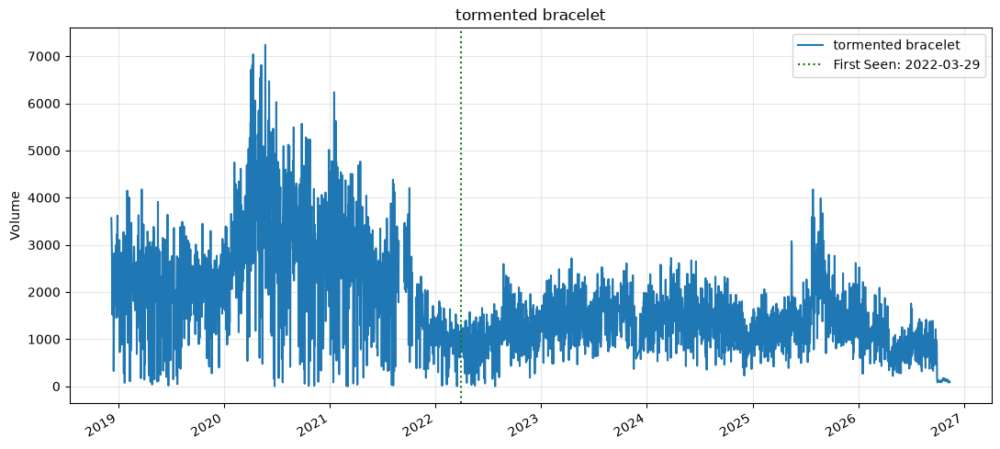

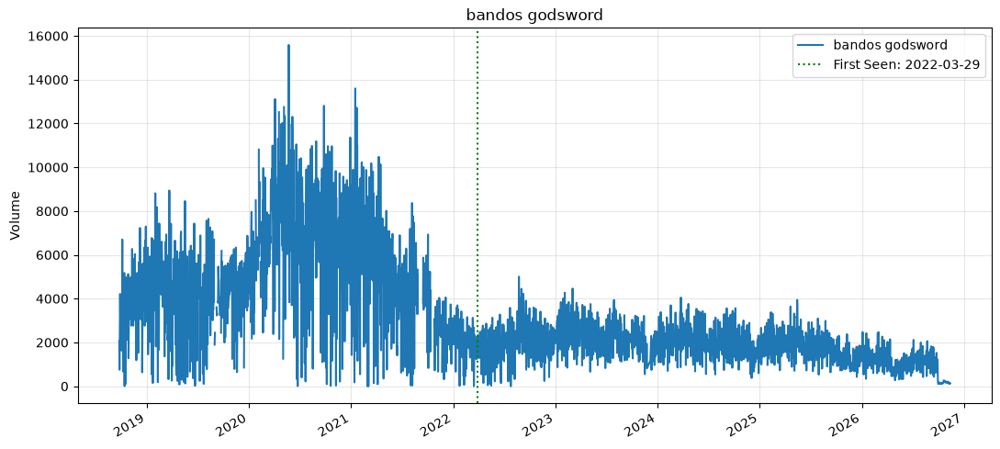

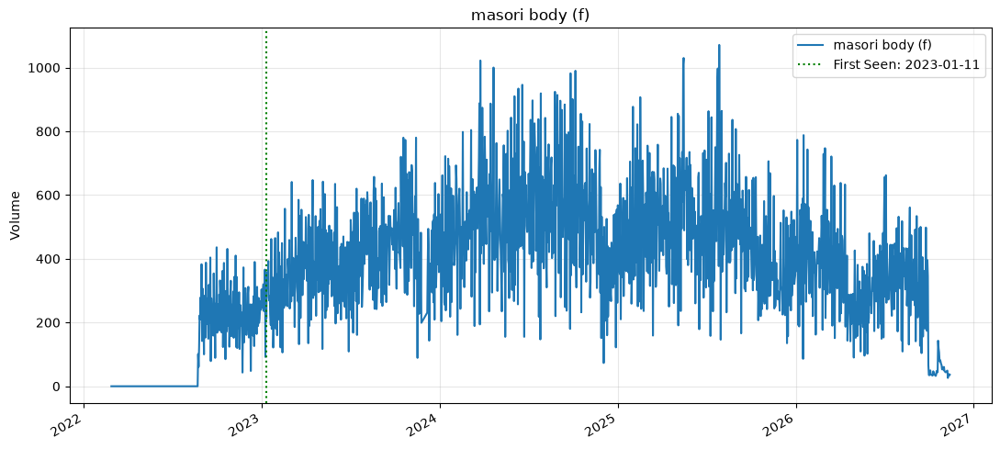

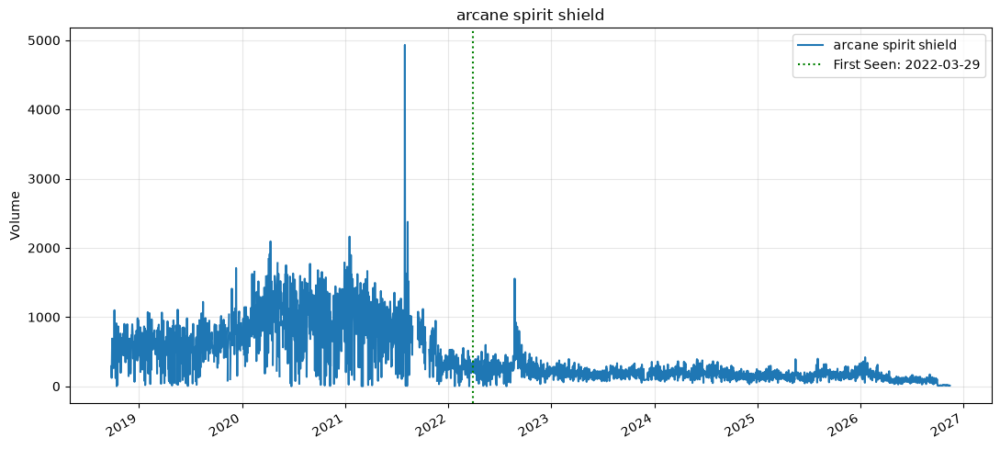

In [487]:
for item in unique_items:
    plot_items_volume(sinkHistDF, item)

In [504]:
def before_after_avg_volume(df, items=None, col="volume"):
    d = df.copy()
    if items is not None:
        d = d[d["item"].isin(items)]

    # Build a tz-aware date from the ms timestamp (more reliable than the `date` column)
    d["_date"] = pd.to_datetime(d["timestamp"], unit="ms", utc=True)
    d["_first_seen"] = pd.to_datetime(d["first_seen"], utc=True, errors="coerce")

    d["period"] = np.where(d["_date"] < d["_first_seen"], "before", "after")

    avgs = (d.groupby(["item", "period"])[col].mean()
              .unstack("period")
              .reindex(columns=["before", "after"]))
    return avgs


def plot_before_after_volume(df, items=None, col="volume", log=False, title=None, sort_by="before"):
    avgs = before_after_avg(df, items, col)
    if sort_by:
        avgs = avgs.sort_values(sort_by)

    ax = avgs.plot(kind="barh", figsize=(10, max(5, len(avgs) * 0.4)), logx=log, width=0.8,
                   title=title or f"Average {col} before vs after First Seen")
    ax.set_xlabel(f"Average {col}")
    ax.set_ylabel("")
    ax.grid(alpha=0.3, axis="x")
    plt.tight_layout()
    plt.show()

    return avgs

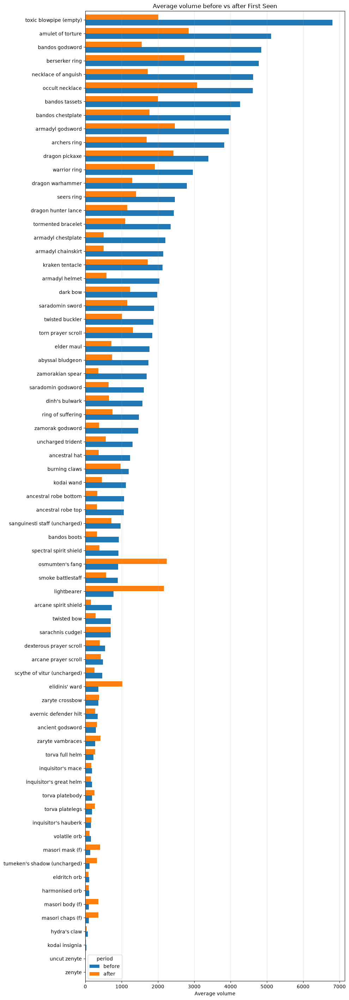

period,before,after
item,,
zenyte,7.077670,5.069697
uncut zenyte,13.154374,6.361111
kodai insignia,25.731100,21.960101
hydra's claw,68.398941,41.917677
masori chaps (f),100.539432,355.655844
...,...,...
necklace of anguish,4619.339071,1715.532828
berserker ring,4773.677419,2726.512626
bandos godsword,4845.798333,1556.099495


In [505]:
plot_before_after_volume(sinkHistDF,unique_items)

In [516]:
def plot_before_after_price(df, items=None, col="price", title=None, sort_ascending=True):
    avgs = before_after_avg_price(df, items, col)
    pct = ((avgs["after"] / avgs["before"] - 1) * 100).dropna()   # items missing before/after are dropped
    pct = pct.sort_values(ascending=sort_ascending)

    colors = ["tab:green" if v >= 0 else "tab:red" for v in pct]
    ax = pct.plot(kind="barh", figsize=(10, max(5, len(pct) * 0.4)),
                  color=colors, width=0.8,
                  title=title or f"% change in average {col} after First Seen")

    ax.bar_label(ax.containers[0], labels=[f"{v:+.0f}%" for v in pct], padding=3, fontsize=9)
    ax.axvline(0, color="black", linewidth=0.8)
    ax.margins(x=0.12)
    ax.set_xlabel(f"% change in average {col} (after vs before)")
    ax.set_ylabel("")
    ax.grid(alpha=0.3, axis="x")
    plt.tight_layout()
    plt.show()

    return pct.to_frame("pct_change").join(avgs)

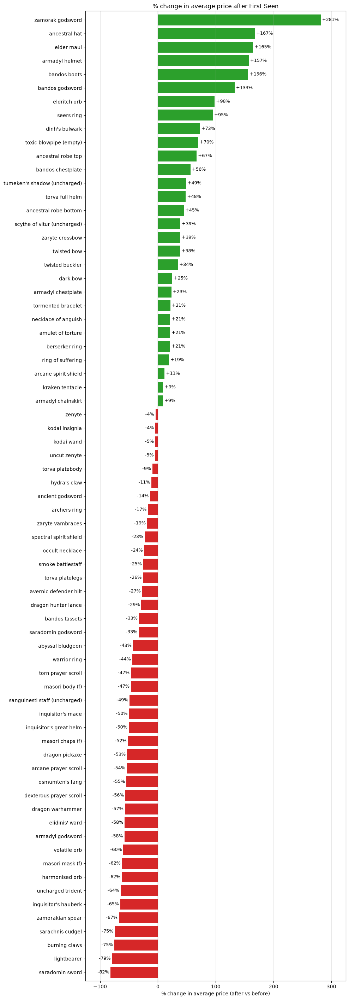

,pct_change,before,after
item,,,
saradomin sword,-81.778464,9.640141e+05,1.756582e+05
lightbearer,-79.342210,1.758419e+07,3.632505e+06
burning claws,-75.055275,1.877061e+07,4.682278e+06
sarachnis cudgel,-74.589815,7.214072e+05,1.833109e+05
zamorakian spear,-67.453386,1.077713e+07,3.507592e+06
...,...,...,...
bandos boots,156.198939,2.452379e+05,6.282968e+05
armadyl helmet,156.909332,3.743921e+06,9.618483e+06
elder maul,164.640143,2.723618e+07,7.207787e+07


In [517]:
plot_before_after_price(sinkHistDF,unique_items)

In [520]:

def pct_change_table(df, items=None, price_col="price", vol_col="volume"):
    p = before_after_avg_price(df, items, price_col)
    v = before_after_avg_price(df, items, vol_col)
    out = pd.DataFrame({
        "price_pct":  (p["after"] / p["before"] - 1) * 100,
        "volume_pct": (v["after"] / v["before"] - 1) * 100,
    })
    return out.replace([np.inf, -np.inf], np.nan).dropna()

def plot_price_vs_volume_change(df, items=None, price_col="price", vol_col="volume",
                                sort_by="price_pct", title=None):
    pct = pct_change_table(df, items, price_col, vol_col).sort_values(sort_by)

    ax = pct[["price_pct", "volume_pct"]].plot(
        kind="barh", figsize=(10, max(5, len(pct) * 0.6)), width=0.8,
        color=["tab:blue", "tab:orange"],
        title=title or "% change in average price vs volume after First Seen")

    for c in ax.containers:
        ax.bar_label(c, fmt="%+.0f%%", padding=3, fontsize=8)

    ax.axvline(0, color="black", linewidth=0.8)
    ax.margins(x=0.12)
    ax.set_xlabel("% change (after vs before)")
    ax.set_ylabel("")
    ax.legend(["Price", "Volume"])
    ax.grid(alpha=0.3, axis="x")
    plt.tight_layout()
    plt.show()
    return pct

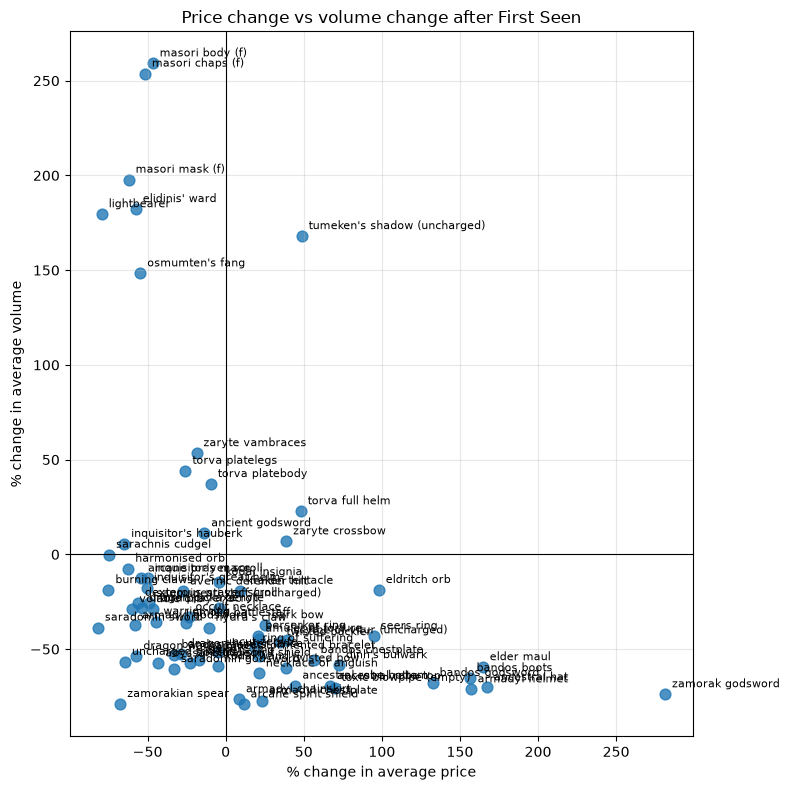

,price_pct,volume_pct
item,,
abyssal bludgeon,-43.052133,-57.528945
amulet of torture,21.022171,-44.456795
ancestral hat,167.424666,-70.187636
ancestral robe bottom,44.688388,-69.289340
ancestral robe top,66.917174,-69.521991
...,...,...
zamorak godsword,281.349082,-73.823424
zamorakian spear,-67.453386,-78.933617
zaryte crossbow,38.738042,6.893495


In [521]:
scatter_price_vs_volume(sinkHistDF)

In [523]:
def divergent_items(df, items=None, price_col="price", vol_col="volume", mode="both"):
    """
    mode:
      "price_up_vol_down" -> gained value, lost volume
      "price_down_vol_up" -> lost value, gained volume
      "both"              -> either divergence
    """
    pct = pct_change_table(df, items, price_col, vol_col)

    up_down = (pct["price_pct"] > 0) & (pct["volume_pct"] < 0)
    down_up = (pct["price_pct"] < 0) & (pct["volume_pct"] > 0)

    mask = {"price_up_vol_down": up_down,
            "price_down_vol_up": down_up,
            "both": up_down | down_up}[mode]
    return pct[mask]


def plot_price_vs_volume_change(df, items=None, price_col="price", vol_col="volume",
                                sort_by="price_pct", title=None, mode=None):
    pct = pct_change_table(df, items, price_col, vol_col)

    if mode is not None:
        keep = divergent_items(df, items, price_col, vol_col, mode).index
        pct = pct.loc[keep]

    if pct.empty:
        print("No items match that filter.")
        return pct

    pct = pct.sort_values(sort_by)

    ax = pct[["price_pct", "volume_pct"]].plot(
        kind="barh", figsize=(10, max(5, len(pct) * 0.6)), width=0.8,
        color=["tab:blue", "tab:orange"],
        title=title or "% change in average price vs volume after First Seen")

    for c in ax.containers:
        ax.bar_label(c, fmt="%+.0f%%", padding=3, fontsize=8)

    ax.axvline(0, color="black", linewidth=0.8)
    ax.margins(x=0.12)
    ax.set_xlabel("% change (after vs before)")
    ax.set_ylabel("")
    ax.legend(["Price", "Volume"])
    ax.grid(alpha=0.3, axis="x")
    plt.tight_layout()
    plt.show()
    return pct

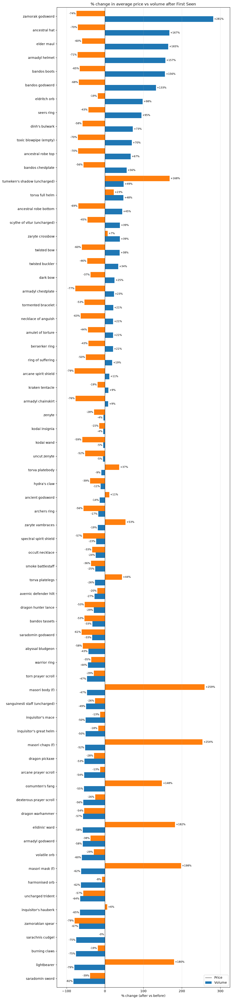

,price_pct,volume_pct
item,,
saradomin sword,-81.778464,-38.616497
lightbearer,-79.342210,179.522182
burning claws,-75.055275,-18.857233
sarachnis cudgel,-74.589815,-0.123637
zamorakian spear,-67.453386,-78.933617
...,...,...
bandos boots,156.198939,-65.330283
armadyl helmet,156.909332,-71.223947
elder maul,164.640143,-59.537934


In [524]:
plot_price_vs_volume_change(sinkHistDF)

# filter the history for https://oldschool.runescape.wiki/w/Grand_Exchange?action=history&limit=500&offset= to dec 9 2021


In [ ]:
# Just the table
divergent_items(df, mode="price_up_vol_down")
divergent_items(df, mode="price_down_vol_up")

# Plots
plot_price_vs_volume_change(df, mode="price_up_vol_down",
                            title="Price up, volume down")
plot_price_vs_volume_change(df, mode="price_down_vol_up",
                            title="Price down, volume up")
plot_price_vs_volume_change(df, mode="both")

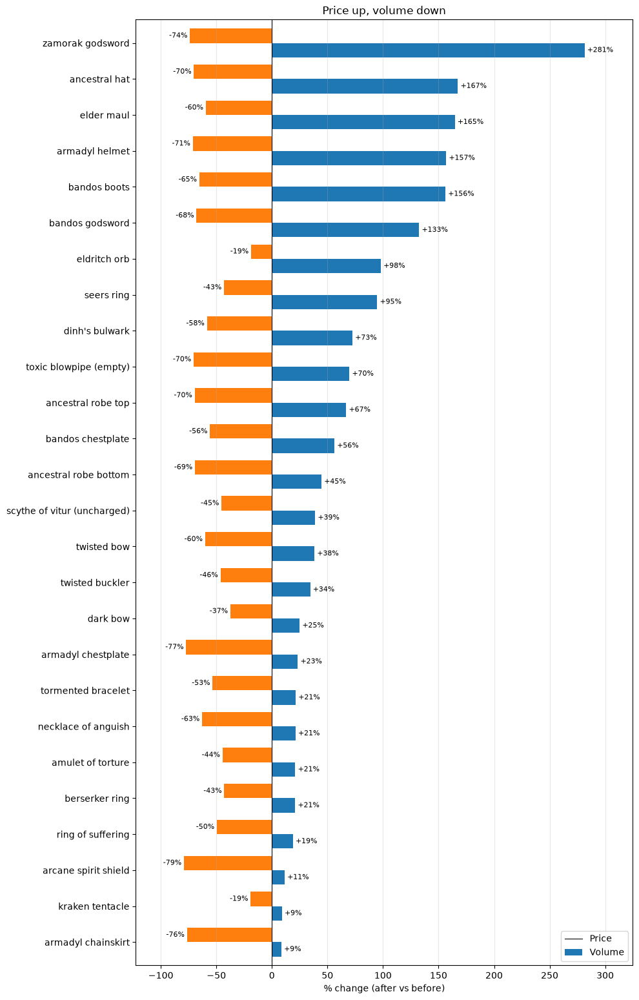

,price_pct,volume_pct
item,,
armadyl chainskirt,8.567776,-76.476796
kraken tentacle,9.088641,-19.190395
arcane spirit shield,11.485451,-79.197358
ring of suffering,18.951880,-49.565070
berserker ring,20.935256,-42.884439
amulet of torture,21.022171,-44.456795
necklace of anguish,21.268369,-62.861942
tormented bracelet,21.467515,-53.405044
armadyl chestplate,23.307036,-77.211109


In [525]:
plot_price_vs_volume_change(sinkHistDF, mode="price_up_vol_down",
                            title="Price up, volume down")

In [526]:
def plot_price_vs_volume_scatter(df, items=None, price_col="price", vol_col="volume",
                                 mode=None, title=None, symlog=False, label=True):
    """
    Scatter of % change in price (x) vs % change in volume (y).
    Top-left     = price up, volume down
    Bottom-right = price down, volume up
    mode: None (all items), "price_up_vol_down", "price_down_vol_up", or "both"
    symlog: use a symmetric log scale if a few items have huge % changes
    """
    pct = pct_change_table(df, items, price_col, vol_col)

    if mode is not None:
        pct = pct.loc[divergent_items(df, items, price_col, vol_col, mode).index]

    if pct.empty:
        print("No items match that filter.")
        return pct

    # color by quadrant
    up_down = (pct["price_pct"] > 0) & (pct["volume_pct"] < 0)
    down_up = (pct["price_pct"] < 0) & (pct["volume_pct"] > 0)
    colors = np.where(up_down, "tab:green",
             np.where(down_up, "tab:red", "tab:gray"))

    fig, ax = plt.subplots(figsize=(9, 7))
    ax.scatter(pct["price_pct"], pct["volume_pct"], c=colors, s=70,
               edgecolor="black", linewidth=0.5, zorder=3)

    if label:
        for name, row in pct.iterrows():
            ax.annotate(name, (row["price_pct"], row["volume_pct"]),
                        xytext=(5, 5), textcoords="offset points", fontsize=8)

    ax.axhline(0, color="black", linewidth=0.8)
    ax.axvline(0, color="black", linewidth=0.8)

    if symlog:
        ax.set_xscale("symlog", linthresh=10)
        ax.set_yscale("symlog", linthresh=10)

    # quadrant captions
    ax.text(0.02, 0.98, "Price down, volume up" if False else "Price down\nVolume up",
            transform=ax.transAxes, va="top", ha="left", color="tab:red", alpha=0.6)
    ax.text(0.98, 0.02, "Price up\nVolume down",
            transform=ax.transAxes, va="bottom", ha="right", color="tab:green", alpha=0.6)

    ax.set_xlabel("% change in average price (after vs before)")
    ax.set_ylabel("% change in average volume (after vs before)")
    ax.set_title(title or "Price vs volume change after First Seen")
    ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()
    return pct

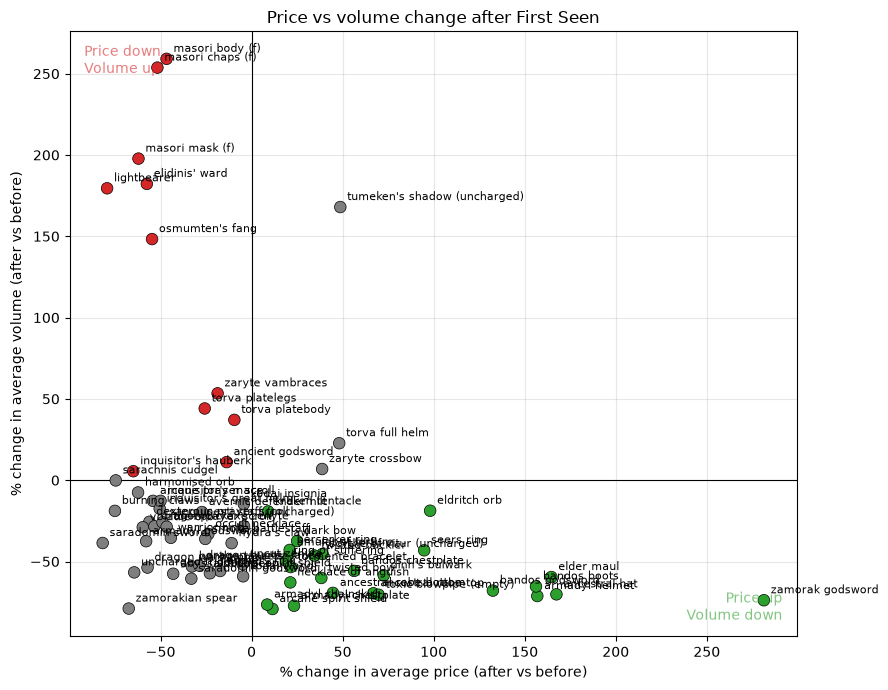

,price_pct,volume_pct
item,,
abyssal bludgeon,-43.052133,-57.528945
amulet of torture,21.022171,-44.456795
ancestral hat,167.424666,-70.187636
ancestral robe bottom,44.688388,-69.289340
ancestral robe top,66.917174,-69.521991
...,...,...
zamorak godsword,281.349082,-73.823424
zamorakian spear,-67.453386,-78.933617
zaryte crossbow,38.738042,6.893495


In [527]:
plot_price_vs_volume_scatter(sinkHistDF)

In [597]:
import seaborn as sb
import matplotlib.pyplot as plt

def plot_price_vs_volume_heatmap(df, items=None, price_col="price", vol_col="volume",
                                 sort_by="price_pct", title=None, mode=None,
                                 normalize=True, cmap="RdBu"):
    """
    normalize=True : color each column by its own scale (so a huge volume swing
                     doesn't wash out the price column); numbers shown are still
                     the real % changes.
    normalize=False: one shared color scale across both columns.
    """
    pct = pct_change_table(df, items, price_col, vol_col)

    if mode is not None:
        keep = divergent_items(df, items, price_col, vol_col, mode).index
        pct = pct.loc[keep]

    if pct.empty:
        print("No items match that filter.")
        return pct

    pct = pct.sort_values(sort_by, ascending=False)
    data = pct[["price_pct", "volume_pct"]]

    # Color values: scale each column by its max absolute change, keeping 0 as the midpoint
    if normalize:
        color_data = data / data.abs().max()
        vmin, vmax = -1, 1
    else:
        lim = data.abs().to_numpy().max()
        color_data, vmin, vmax = data, -lim, lim

    # Annotations are the true percentages
    annot = data.map(lambda v: f"{v:+.0f}%")   # use .applymap on pandas < 2.1


    plt.show()

    fig, ax = plt.subplots(figsize=(6, max(4, len(pct) * 0.5)))
    sb.heatmap(color_data, annot=annot, fmt="", cmap=cmap, center=0,
                vmin=vmin, vmax=vmax, linewidths=0.5, linecolor="white",
                cbar=not normalize, ax=ax)

    ax.set_xticklabels(["Price", "Volume"], rotation=0)
    ax.set_ylabel("")
    ax.set_title(title or "% change in average price vs volume after First Seen")
    plt.tight_layout()
    plt.show()
    return pct

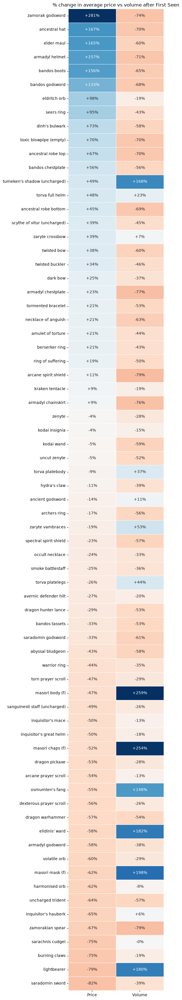

,price_pct,volume_pct
item,,
zamorak godsword,281,-74
ancestral hat,167,-70
elder maul,165,-60
armadyl helmet,157,-71
bandos boots,156,-65
...,...,...
zamorakian spear,-67,-79
sarachnis cudgel,-75,-0
burning claws,-75,-19


In [598]:
plot_price_vs_volume_heatmap(sinkHistDF)

<!-- # Ways to estimate it

# Estimate creation, then back out destruction. For a drop-sourced item like the Twisted bow or Scythe, use kill or completion counts (hiscores deltas), multiplied by the drop rate. This gives expected new items per day. If you also have an independent estimate of total supply, destruction = created - Δsupply. Total supply is the weak link, since Jagex doesn’t publish it, so you’d be relying on a rough anchor like an old estimate or a mod statement.
# Use price as a signal of supply change. If you assume a demand elasticity ε, then roughly ΔQ/Q ≈ -(ΔP/P)/ε. For mega-rares ε is hard to pin down, so treat the output as a range, not a point estimate.
# Event studies. Find moments where a sink or source changed suddenly: an update that adds a use for the item, a change to death mechanics, or a ban wave. Compare price and volume before and after against a comparison item (a difference-in-differences setup). The effect size gives you a supply-shift estimate tied to a known cause.
# Turnover ratio. Daily volume divided by estimated supply tells you how liquid the item is. A drop in volume with flat prices usually means fewer sellers or hoarding, not destruction.

# Things to watch for

# Items on inactive or banned accounts are effectively removed but not destroyed, and you can’t distinguish the two in the data.
# Volume from the Weird Gloop API is a flow measure, so don’t sum it as if it were a stock.
# Any “items removed” number will come with wide uncertainty. I’d report it as a range with your assumptions stated. -->

Ways to estimate it

Estimate creation, then back out destruction. For a drop-sourced item like the Twisted bow or Scythe, use kill or completion counts (hiscores deltas), multiplied by the drop rate. This gives expected new items per day. If you also have an independent estimate of total supply, destruction = created - Δsupply. Total supply is the weak link, since Jagex doesn’t publish it, so you’d be relying on a rough anchor like an old estimate or a mod statement.

Use price as a signal of supply change. If you assume a demand elasticity ε, then roughly ΔQ/Q ≈ -(ΔP/P)/ε. For mega-rares ε is hard to pin down, so treat the output as a range, not a point estimate.

Event studies. Find moments where a sink or source changed suddenly: an update that adds a use for the item, a change to death mechanics, or a ban wave. Compare price and volume before and after against a comparison item (a difference-in-differences setup). The effect size gives you a supply-shift estimate tied to a known cause.

Turnover ratio. Daily volume divided by estimated supply tells you how liquid the item is. A drop in volume with flat prices usually means fewer sellers or hoarding, not destruction.

Things to watch for

Items on inactive or banned accounts are effectively removed but not destroyed, and you can’t distinguish the two in the data.
Volume from the Weird Gloop API is a flow measure, so don’t sum it as if it were a stock.
Any “items removed” number will come with wide uncertainty. I’d report it as a range with your assumptions stated.

In [567]:
sinkHistDF

,id,item,timestamp,price,volume,date,first_seen,last_seen
0,6733,archers ring,1427500800000,3603798,NaN,2015-03-28 00:00:00,2022-03-29 07:11:23,2026-10-16 02:02:43+00:00
1,6733,archers ring,1427587200000,3593285,NaN,2015-03-29 00:00:00,2022-03-29 07:11:23,2026-10-16 02:02:43+00:00
2,6733,archers ring,1427673600000,3554174,NaN,2015-03-30 00:00:00,2022-03-29 07:11:23,2026-10-16 02:02:43+00:00
3,6733,archers ring,1427760000000,3531218,NaN,2015-03-31 00:00:00,2022-03-29 07:11:23,2026-10-16 02:02:43+00:00
4,6733,archers ring,1427846400000,3516752,NaN,2015-04-01 00:00:00,2022-03-29 07:11:23,2026-10-16 02:02:43+00:00
...,...,...,...,...,...,...,...,...
255589,12825,arcane spirit shield,1794550859000,98896275,4,2026-11-13 06:20:59,2022-03-29 07:11:23,2026-10-16 02:02:43+00:00
255590,12825,arcane spirit shield,1794564190000,98896275,7,2026-11-13 10:03:10,2022-03-29 07:11:23,2026-10-16 02:02:43+00:00
255591,12825,arcane spirit shield,1794577380000,98896275,8,2026-11-13 13:43:00,2022-03-29 07:11:23,2026-10-16 02:02:43+00:00
255592,12825,arcane spirit shield,1794591372000,98896275,15,2026-11-13 17:36:12,2022-03-29 07:11:23,2026-10-16 02:02:43+00:00


In [658]:
sinkHistDFitemGroups = sinkHistDF.groupby('item').agg({'price':'mean','volume': 'mean','first_seen':'min'})
sinkHistDFitemGroups

# for row in sinkHistDF.itertuples(index=False):
#     row.groupby(['item'])
    # plt.clf()
    # g = sb.pairplot(row.groupby['item'].reset_index()[["volume","price","date","item"]],hue="item",diag_kind="hist",kind="reg")
    
    # if g.legend is not None:
    #     g.legend.remove()
    
    # plt.show()

,price,volume,first_seen
item,,,
abyssal bludgeon,"25,615,066","1,115",2022-03-29 07:11:23
amulet of torture,"15,498,565","3,696",2022-03-29 07:11:23
ancestral hat,"30,770,208",697,2022-03-29 07:11:23
ancestral robe bottom,"86,925,464",607,2022-03-29 07:11:23
ancestral robe top,"107,302,689",600,2022-03-29 07:11:23
...,...,...,...
zamorak godsword,"8,954,078",795,2022-03-29 07:11:23
zamorakian spear,"7,548,218",869,2022-03-29 07:11:23
zaryte crossbow,"344,968,181",377,2023-01-11 12:39:29


In [652]:

# plt.clf()
# g = sb.pairplot(sinkHistDFitemGroups.reset_index()[["volume","price","first_seen","item"]],hue="item",diag_kind="hist",kind="reg")

# if g.legend is not None:
#     g.legend.remove()

# plt.show()


for row in df.itertuples(index=False):
    plt.clf()
    g = sb.pairplot(row[["volume","price","first_seen","item"]],hue="item",diag_kind="hist",kind="reg")
    
    if g.legend is not None:
        g.legend.remove()
    
    plt.show()

TypeError: tuple indices must be integers or slices, not list

<Figure size 640x480 with 0 Axes>

KeyboardInterrupt: 

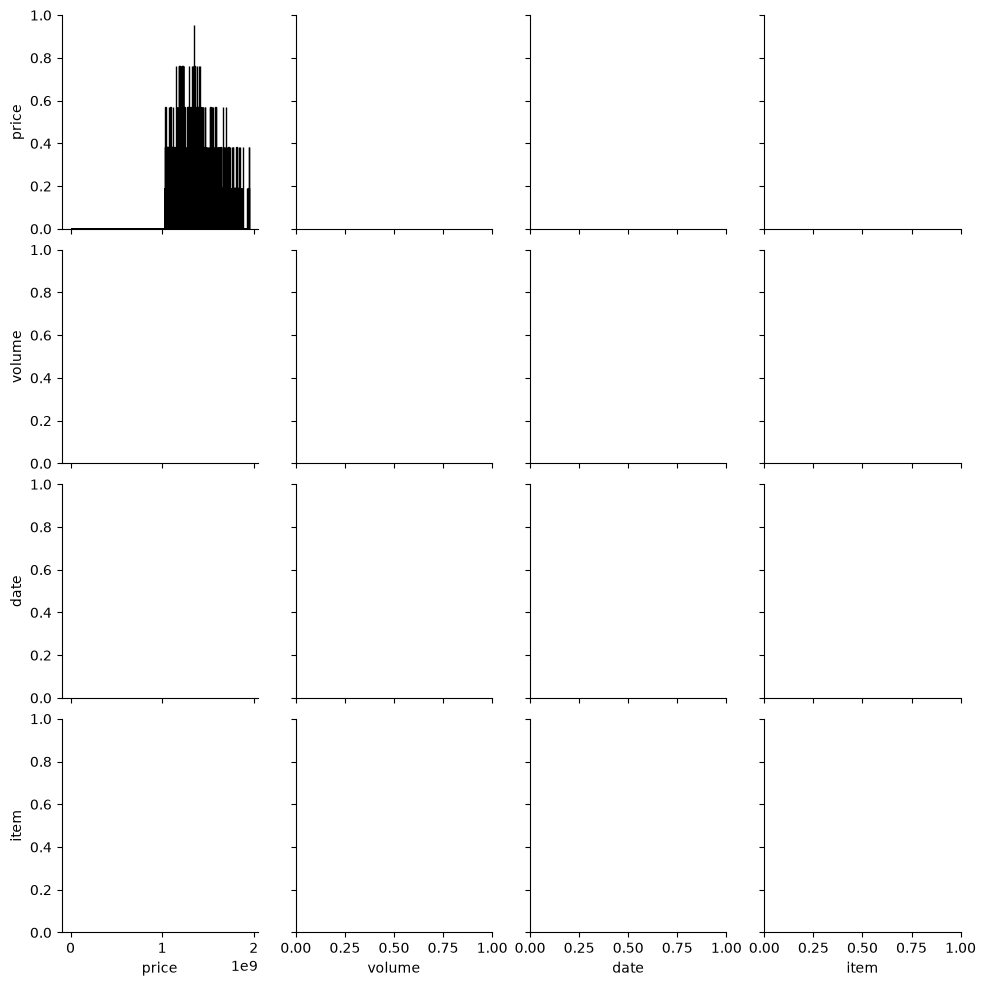

In [661]:
import seaborn as sb
import matplotlib.pyplot as plt

plot_df = sinkHistDF.reset_index()

g = sb.pairplot(
    plot_df,
    vars=["price", "volume", 'date', 'item'],
    hue="price",
    diag_kind="hist",
    kind="reg"
)

plt.show()